In [1]:
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import pytz

### Get Candidate Locations for our GS 
```get_candidate_locs``` returns candidate clusters or groups, their centroids (serve as coarse location of GS candidates) 
and the satellites associates with each cluster

Initial number of candidate location clusters: 686
Possible: 67
Centroid of group  0 : [  42.80378728 -105.42894268]
Point that minimizes distance to each satellite trajectory : 42.672162145334184 -104.53456226636573
sats in group: ['STARLINK-1148', 'STARLINK-5715', 'STARLINK-30231', 'STARLINK-3668', 'STARLINK-30153', 'STARLINK-1873', 'STARLINK-5745', 'STARLINK-1845']


/home/jidazhang/Desktop/new_ws/starlink_ofdm/Starloc/utils/satid_blind_identification.py:89: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Centroid of group  1 : [ 42.67735873 -99.55822861]
Point that minimizes distance to each satellite trajectory : 42.25283425263062 -100.8404745720121
sats in group: ['STARLINK-1233', 'STARLINK-5513', 'STARLINK-2115', 'STARLINK-5715', 'STARLINK-4746', 'STARLINK-2046', 'STARLINK-5436', 'STARLINK-4770']
Centroid of group  2 : [ 39.89295244 -90.6459142 ]
Point that minimizes distance to each satellite trajectory : 39.95896108226503 -91.55830770479784
sats in group: ['STARLINK-1603', 'STARLINK-30507', 'STARLINK-5907', 'STARLINK-5074', 'STARLINK-5934', 'STARLINK-5934', 'STARLINK-3370', 'STARLINK-1846']
Centroid of group  3 : [  34.03442415 -101.87297399]
Point that minimizes distance to each satellite trajectory : 34.50627582945563 -101.79020126644585
sats in group: ['STARLINK-1610', 'STARLINK-30435', 'STARLINK-2101', 'STARLINK-30410', 'STARLINK-5451', 'STARLINK-5650', 'STARLINK-31142', 'STARLINK-2351']
Centroid of group  4 : [ 47.1439054  -68.53089154]
Point that minimizes distance to each s

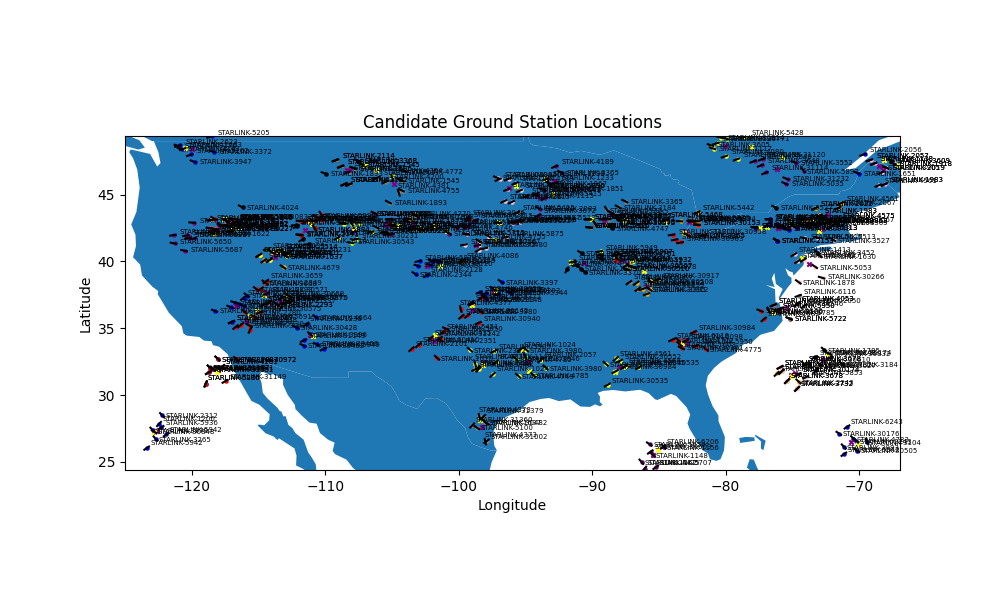

In [3]:
capture_file_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_51_14_freq_11_325G_bw_2.0M_ts_1709697074.3228533_inrx0.dat'
imu_file_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_03_50_54.txt'
start_time = datetime.fromtimestamp(float(capture_file_path.split('_')[-2]), tz=pytz.utc)
tle_path = '/home/jidazhang/Desktop/new_ws/starlink_ofdm/Starloc/6Mar2024_03_51/Starlink.tle'
mat = sio.loadmat('/home/jidazhang/Desktop/new_ws/starlink_ofdm/Starloc/6Mar2024_03_51/phase_comp.mat')
tracked_peaks = mat['dopp_track_dict'][0]
time_arr = []
for arr in tracked_peaks:
    time = np.median(np.real(arr[:,0]))
    time_arr.append(time)
## time_arr.append(580.0)
# sort time_arr
time_arr = sorted(time_arr)
%matplotlib widget
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs
search_radius = 180 # in km
gs_groups, coarse_gs, sat_groups = get_candidate_locs(start_time, time_arr, tle_path, search_dist_bound=search_radius, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_file_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=15)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Candidate Ground Station Locations')
plt.show()

### Narrowing down to a single candidate GS location
- The idea is to compare the observed phase difference at our receiver/GS with the simulated phase differences at the candidate GS locations. 
- The best match results in a single candidate GS. 
- The satellites that are observed by this GS at time in time array will be the SAT IDs.

##### 1. Simulating to get phase difference for all satellites observed by all ground stations at times in time_arr

In [8]:
## Simulating to get phase differences 
## =================================================
from sat_id import faster_doppler_sim
import pickle
import os

filesavepath = '5Feb2024_23-58-08/satdictlist_for_each_gs.pkl'
load = True
# If kernel restarts or if satdictlist_for_each_gs.pkl is already, load it.
if load == True and os.path.exists(filesavepath):
    with open(filesavepath, 'rb') as f:
        satdictlist_for_each_gs = pickle.load(f)
else:
    # get satellite dopp dict for sats associated with each gs
    capture_start_timestamp = float(capture_file_path.split('_')[-2])
    print("start time: ", datetime.fromtimestamp(capture_start_timestamp, tz=pytz.utc))
    satdictlist_for_each_gs = [{} for i in range(len(coarse_gs))]

    #for each satellite at >75 degree min elevation wrt candidate gs, get the dopp, az, alt, range for about 10 secs around time in time_arr
    for gs_idx,cgs in enumerate(coarse_gs):
        for time in time_arr:
            # cgs = wgs84.latlon(cgs[0], cgs[1])
            # get sat dopp dict 
            date = '_'
            tle_path = tle_path
            fc = 11.325e9
            t_start = capture_start_timestamp + time - 5
            t_stop = capture_start_timestamp + time + 5
            t_step = 1
            gs = cgs
            # get sat dopp dict for this gs 
            sat_dopp_dict, _ = faster_doppler_sim(date, tle_path, fc, t_start, t_stop, t_step, gs, min_ele=75)
            satdictlist_for_each_gs[gs_idx][time] = sat_dopp_dict

    with open(filesavepath, 'wb') as f:
        pickle.dump(satdictlist_for_each_gs, f)

start time:  2024-03-06 03:51:14.322853+00:00
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  3
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  3
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10

KeyboardInterrupt: 

###### 

##### 2. From the simulated alt, az, etc. get the phase differences and the parameters fro each phase difference line (slope and intercept)

In [5]:
# get phase diff params or all sats in each group
from utils.satid_blind_identification import get_phase_diff_params_allsatsingroups
phasediffdict_for_each_gs, phase_diff_param = get_phase_diff_params_allsatsingroups(coarse_gs, satdictlist_for_each_gs, time_arr)

GS 0 Time 43.5610005


KeyError: 43.5610005

##### 3. Find the GS where the simulated phase difference parameters minimize the distance to the observed phase difference parameters

In [6]:
# find gs where the parameters minimize the difference with the observed phase diff
from utils.satid_blind_identification import find_best_coarse_gs
observed_phase_diff_param = sio.loadmat('5Feb2024_23-58-08/phase_comp_satid.mat')['phase_diff_param'][0]
best_coarse_gs_candidate, best_candidate_idx, min_param_diff_pertime_each_gs, min_param_diff_sat_pertime_each_gs = find_best_coarse_gs(
                                                                                                coarse_gs, 
                                                                                                time_arr,
                                                                                                satdictlist_for_each_gs, 
                                                                                                phase_diff_param, 
                                                                                                observed_phase_diff_param)

Best GS: [ 40.57796894 -87.64195092] Min Param Diff: 0.33176841377681965
All other GS centroids and their respective min param diff:

[ 29.19634675 -99.89766455] 2.069066829120171
[  41.80668316 -121.62435425] 1.4666570878861824
[  43.37734658 -111.75533912] 1.9633745302184649
[ 40.03729283 -81.79407142] 1.0421716191934631
[ 41.23279744 -94.18566899] 1.5909059220480326
[  32.40739323 -118.10517728] 2.1163902211707493
[ 28.47924625 -92.08576498] 1.714633521085727
[  39.97880504 -114.48801137] 2.3101204835761906
[  40.07556833 -114.24707001] 2.3005525823413397
[ 42.5222797  -87.72362015] 1.214614917597386
[  32.42321317 -118.10741949] 2.1164107850112117
[  43.27620343 -103.36737176] 0.7839684295708121
[ 38.38755965 -68.58493323] 2.3708935663456137
[  43.0655929  -111.63979365] 1.848145373685419
[ 40.57796894 -87.64195092] 0.33176841377681965
[  38.29908639 -108.70694789] 1.0097779113435255
[  42.97291136 -103.66387723] 0.9312343166596789
[  43.04955088 -118.76036543] 2.2098159388325276
[

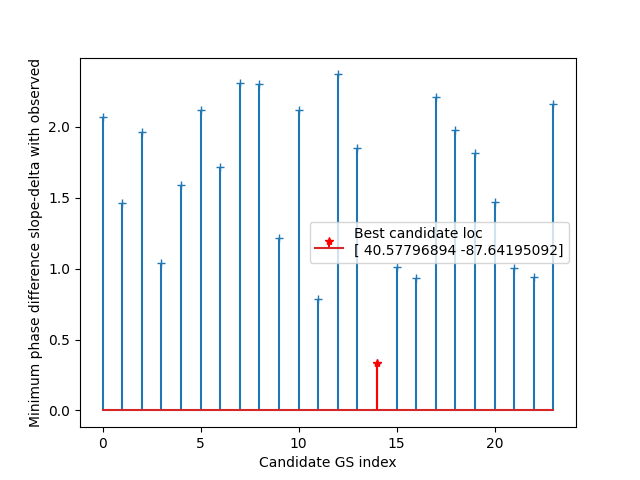

14

In [7]:
plt.figure()
plt.stem(range(len(coarse_gs)), np.sum(min_param_diff_pertime_each_gs, axis=1), markerfmt='+')
plt.stem(best_candidate_idx, np.sum(min_param_diff_pertime_each_gs, axis=1)[best_candidate_idx],markerfmt='*', linefmt='r', label='Best candidate loc\n'+str(best_coarse_gs_candidate))
plt.xlabel('Candidate GS index')
plt.ylabel('Minimum phase difference slope-delta with observed')
plt.legend()
plt.show()
best_candidate_idx

### Save data needed for localization

In [8]:
def get_distkm_latlon_coordinates_(lat1, lat2, dlat, dlon):
    # all coordinates in radians
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    dist = 2 * np.arcsin(np.sqrt(a))*6371 # in km
    return dist

In [13]:
save_dict = {}
save_dict['real_gs'] = lat_lon_alt_mean
save_dict['centroid_gs'] = best_coarse_gs_candidate
save_dict['search_radius'] = search_radius
# get farthest gs in the candidate gs_group

from utils.helper import get_distkm_latlon_coordinates

loc1 = lat_lon_alt_mean[:2]
loc2 = gs_groups[best_candidate_idx]
dists = get_distkm_latlon_coordinates(loc1, loc2)
farthest_gs_idx = np.argmax(dists)
farthest_gs = gs_groups[best_candidate_idx][farthest_gs_idx]
d1 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d2 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d3 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))
d4 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))

save_dict['farthest_gs'] = farthest_gs
save_dict['d1'] = d1 # distance to left/west boundary
save_dict['d2'] = d2 # distance to right/east boundary
save_dict['d3'] = d3 # distance to top/north boundary
save_dict['d4'] = d4 # distance to bottom/south boundary
print('d1: ', d1, 'd2: ', d2, 'd3: ', d3, 'd4: ', d4)
sio.savemat('5Feb2024_23-58-08/__.mat', save_dict)

d1:  [91.90918921] d2:  [208.09081079] d3:  [273.04991345] d4:  [26.95008655]


In [10]:
from utils.helper import get_distkm_latlon_coordinates

loc1 = lat_lon_alt_mean[:2]
loc2 = gs_groups[best_candidate_idx]
dists = get_distkm_latlon_coordinates(loc1, loc2)
farthest_gs_idx = np.argmax(dists)
farthest_gs = gs_groups[best_candidate_idx][farthest_gs_idx]
d1 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d2 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d3 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))
d4 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))
d1, d2, d3, d4

(array([91.90918921]),
 array([208.09081079]),
 array([273.04991345]),
 array([26.95008655]))